# Cheltenham Road-Corridor Search with TESSERA

This notebook finds 10 m locations near **Cheltenham** that look like high-NO2 UK traffic monitors.
You can change `THRESHOLD` below and re-run the notebook in less than a second.
All AURN, TESSERA, and Cheltenham grid files are cached in `./data/`.


In [1]:
from pathlib import Path

import contextily as cx
import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio.transform
import rasterio.warp
from geotessera import GeoTesseraZarr

from aurn_no2_embeddings import annual_pollutant, extract_full_patches, load_sites, summarize_patches

YEAR = 2023
POLLUTANT = "NO2"
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Bounding box around Cheltenham (~6 km x 5.5 km): town centre, A40, A4019, and Pittville Park.
CHELTENHAM_BBOX = (-2.125, 51.875, -2.035, 51.925)

# Minimum cosine similarity (0 to 1) to count a 10 m pixel as a match.
# Try 0.85 (broad), 0.88 (default), or 0.91 (strict road cores).
THRESHOLDS = [0.85, 0.88, 0.91]

# Set True only to ignore ./data and re-download everything.
FORCE_REFRESH = False

plt.rcParams.update({"figure.dpi": 140, "font.size": 10})

## 1. Load cached UK AURN NO2 station data

We load the 2023 UK AURN monitors that have at least `75%` valid hourly readings (`notNAPercentage >= 0.75`).
If `./data/aurn_no2_2023.csv` exists, we read it from disk.

In [2]:
csv_path = DATA_DIR / f"aurn_{POLLUTANT.lower().replace('.', '')}_{YEAR}.csv"

if csv_path.exists() and not FORCE_REFRESH:
    sites = pd.read_csv(csv_path)
    print(f"Loaded from cache: {csv_path} ({len(sites)} sites)")
else:
    print("Cache miss: downloading AURN metadata and hourly readings...")
    sites = annual_pollutant(load_sites(POLLUTANT), YEAR, pollutant=POLLUTANT)
    sites.to_csv(csv_path, index=False)

print(f"Mean NO2: {sites['no2'].mean():.2f} ug/m3")
display(sites[["code", "site_name", "site_type", "zone", "no2", "notNAPercentage"]].head())
print("\nSite type counts:")
print(sites["site_type"].value_counts())

Loaded from cache: data/aurn_no2_2023.csv (148 sites)
Mean NO2: 16.71 ug/m3


,code,site_name,site_type,zone,no2,notNAPercentage
0,ABD9,Aberdeen Erroll Park,Urban Background,North East Scotland,14.737848,0.992237
1,ABD7,Aberdeen Union Street Roadside,Urban Traffic,North East Scotland,24.484404,0.997831
2,ARM6,Armagh Roadside,Urban Traffic,Northern Ireland,20.815827,0.985388
3,AH,Aston Hill,Rural Background,North Wales,2.739518,0.979452
4,BAAR,Ballymena Antrim Road,Urban Traffic,Northern Ireland,15.358848,0.969977



Site type counts:
site_type
Urban Traffic          63
Urban Background       59
Rural Background       13
Urban Industrial        8
Suburban Background     3
Suburban Industrial     2
Name: count, dtype: int64


## 1b. Plot all UK AURN NO2 monitors on a translucent UK map

This map shows where all 148 UK AURN monitors sit and how NO2 varies across the country.
A cyan star marks **Cheltenham**.


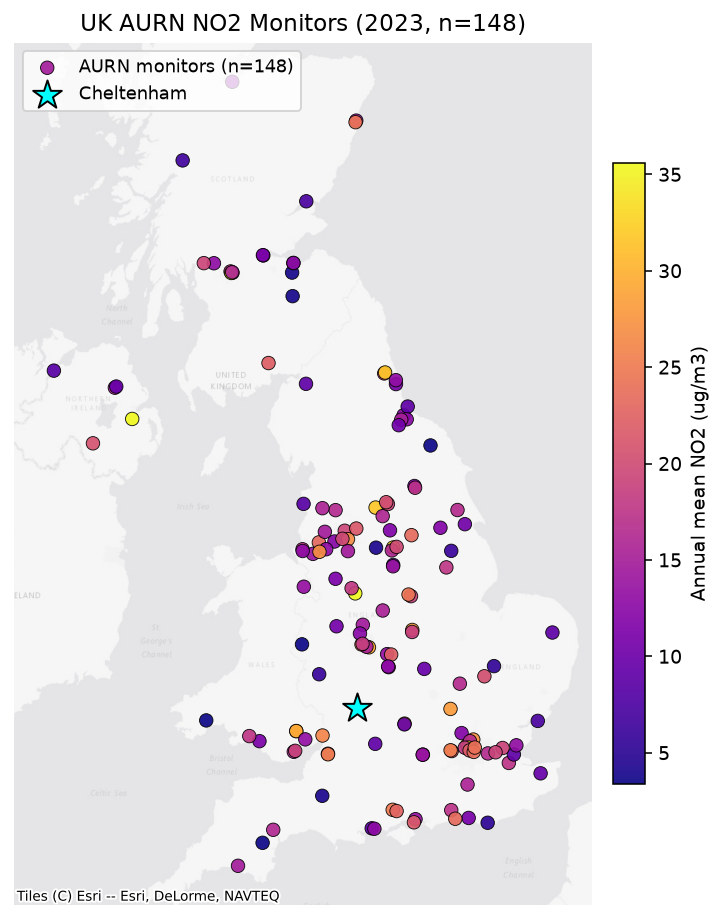

In [3]:
import geopandas as gpd

gdf = gpd.GeoDataFrame(
    sites.copy(),
    geometry=gpd.points_from_xy(sites["lon"], sites["lat"]),
    crs="EPSG:4326",
).to_crs("EPSG:3857")

fig, ax = plt.subplots(figsize=(6.5, 8.0))
vmin, vmax = np.percentile(gdf["no2"], [2, 98])
sc = ax.scatter(
    gdf.geometry.x,
    gdf.geometry.y,
    c=gdf["no2"],
    cmap="plasma",
    vmin=vmin,
    vmax=vmax,
    s=48,
    edgecolors="black",
    linewidths=0.45,
    alpha=0.92,
    zorder=3,
    label=f"AURN monitors (n={len(gdf)})",
)

ch_lon = (CHELTENHAM_BBOX[0] + CHELTENHAM_BBOX[2]) / 2
ch_lat = (CHELTENHAM_BBOX[1] + CHELTENHAM_BBOX[3]) / 2
ch_x, ch_y = rasterio.warp.transform("EPSG:4326", "EPSG:3857", [ch_lon], [ch_lat])
ax.scatter(ch_x, ch_y, marker="*", s=240, c="cyan", edgecolors="black", linewidths=1.0, zorder=5, label="Cheltenham")

xmin, ymin, xmax, ymax = gdf.total_bounds
dx, dy = (xmax - xmin) * 0.08, (ymax - ymin) * 0.05
ax.set_xlim(xmin - dx, xmax + dx)
ax.set_ylim(ymin - dy, ymax + dy)
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, alpha=0.55, attribution_size=7, zorder=1)
fig.colorbar(sc, ax=ax, shrink=0.72, pad=0.03, label="Annual mean NO2 (ug/m3)")
ax.set_axis_off()
ax.set_title(f"UK AURN NO2 Monitors ({YEAR}, n={len(gdf)})")
ax.legend(loc="upper left", frameon=True, fontsize=9)
plt.show()


## 2. Load full 640 m TESSERA patches and extract 10 m vectors

We read the stored `(H, W, 128)` patches from `./data/patches_640m_2023.npz`.
We print the raw patch shapes first, then take the centre 10 m pixel (`point`) for each monitor.

In [4]:
patch_path = DATA_DIR / f"patches_640m_{YEAR}.npz"
if not patch_path.exists() or FORCE_REFRESH:
    extract_full_patches(sites, YEAR, patch_path)
else:
    size_mb = patch_path.stat().st_size / (1024 * 1024)
    print(f"Loaded full patch store: {patch_path} ({size_mb:.1f} MB)")

raw_npz = np.load(patch_path)
raw_shapes = {code: raw_npz[code].shape for code in sites["code"].astype(str) if code in raw_npz}
total_pixels = sum(s[0] * s[1] for s in raw_shapes.values())
print(f"Stored raw patches: {len(raw_shapes)} sites, {total_pixels:,} total 10 m pixels")
print("First 5 raw patch shapes:")
for code, shp in list(raw_shapes.items())[:5]:
    print(f"  {code}: {shp} ({shp[0] * shp[1]:,} pixels x {shp[2]} channels)")

embs = summarize_patches(patch_path, sites["code"])
valid = np.isfinite(embs["point"]).all(axis=1)
df = sites[valid].reset_index(drop=True)
point_emb = embs["point"][valid]
print(f"\nValid sites with finite 10 m vectors: {len(df)} (shape: {point_emb.shape})")

Loaded full patch store: data/patches_640m_2023.npz (184.7 MB)
Stored raw patches: 148 sites, 643,397 total 10 m pixels
First 5 raw patch shapes:
  ABD9: (66, 66, 128) (4,356 pixels x 128 channels)
  ABD7: (66, 66, 128) (4,356 pixels x 128 channels)
  ARM6: (67, 67, 128) (4,489 pixels x 128 channels)
  AH: (64, 64, 128) (4,096 pixels x 128 channels)
  BAAR: (67, 67, 128) (4,489 pixels x 128 channels)

Valid sites with finite 10 m vectors: 144 (shape: (144, 128))


## 3. Build the high-NO2 prototype vector

We pick the 5 monitors with the highest 2023 NO2 levels (`MY1`, `GLA4`, `STKR`, `BEL1`, `SHBR`).
We normalise each 10 m vector to unit length and take their mean to form one search vector (`prototype`).

In [5]:
def l2_normalize(vectors: np.ndarray) -> np.ndarray:
    norms = np.linalg.norm(vectors, axis=-1, keepdims=True)
    return vectors / np.maximum(norms, 1e-12)

point_norm = l2_normalize(point_emb)
top5 = df.sort_values("no2", ascending=False).head(5)
prototype = l2_normalize(point_norm[top5.index.to_numpy()].mean(axis=0, keepdims=True))[0]

print("Top 5 high-NO2 query monitors:")
for _, row in top5.iterrows():
    print(f"  {row['code']:5s}  {row['site_name']:32s}  {row['site_type']:15s}  NO2 = {row['no2']:.2f} ug/m3")

Top 5 high-NO2 query monitors:
  MY1    London Marylebone Road            Urban Traffic    NO2 = 41.62 ug/m3
  GLA4   Glasgow Kerbside                  Urban Traffic    NO2 = 38.97 ug/m3
  STKR   Stoke-on-Trent A50 Roadside       Urban Traffic    NO2 = 35.85 ug/m3
  BEL1   Belfast Stockman's Lane           Urban Traffic    NO2 = 35.55 ug/m3
  SHBR   Sheffield Barnsley Road           Urban Traffic    NO2 = 33.57 ug/m3


## 4. Scan Cheltenham and apply `THRESHOLD`

We stream 10 m TESSERA pixels inside `CHELTENHAM_BBOX` via `iter_region` and score each pixel against `prototype`.
We save all pixel scores to `./data/cheltenham_grid_2023.npz`, so changing `THRESHOLD` does not re-download anything.
Then we keep only pixels with `cosine_similarity >= THRESHOLD`.

In [6]:
grid_cache = DATA_DIR / f"cheltenham_grid_{YEAR}.npz"

if grid_cache.exists() and not FORCE_REFRESH:
    npz = np.load(grid_cache)
    mx, my, lons, lats, sims = npz["mx"], npz["my"], npz["lons"], npz["lats"], npz["sims"]
    print(f"Loaded cached Cheltenham grid: {grid_cache} ({len(sims):,} pixels)")
else:
    print("Cache miss: streaming Cheltenham 10 m grid from GeoTesseraZarr...")
    gt = GeoTesseraZarr()
    xs_list, ys_list, sims_list = [], [], []
    crs_out = ""
    for block, transform, crs in gt.iter_region(CHELTENHAM_BBOX, year=YEAR, strip_rows=512):
        crs_out = crs
        arr = np.asarray(block, dtype=float)
        h, w, c = arr.shape
        flat = arr.reshape(-1, c)
        ok = np.isfinite(flat).all(axis=1)
        if not ok.any():
            continue
        s = l2_normalize(flat[ok]) @ prototype
        rows, cols = np.nonzero(ok.reshape(h, w))
        xs, ys = rasterio.transform.xy(transform, rows, cols)
        xs_list.append(np.asarray(xs, dtype=float))
        ys_list.append(np.asarray(ys, dtype=float))
        sims_list.append(s)

    xs_all = np.concatenate(xs_list)
    ys_all = np.concatenate(ys_list)
    sims = np.concatenate(sims_list).astype(np.float32)
    mx, my = rasterio.warp.transform(crs_out, "EPSG:3857", xs_all, ys_all)
    lons, lats = rasterio.warp.transform(crs_out, "EPSG:4326", xs_all, ys_all)
    mx, my = np.asarray(mx, dtype=np.float32), np.asarray(my, dtype=np.float32)
    lons, lats = np.asarray(lons, dtype=np.float32), np.asarray(lats, dtype=np.float32)
    np.savez_compressed(grid_cache, mx=mx, my=my, lons=lons, lats=lats, sims=sims)
    print(f"Saved cached Cheltenham grid: {grid_cache} ({len(sims):,} pixels)")

print(f"Similarity stats: min={sims.min():.3f}, median={np.median(sims):.3f}, p95={np.percentile(sims, 95):.3f}, max={sims.max():.3f}")
for t in THRESHOLDS:
    m_t = sims >= t
    print(f"  Pixels >= {t:.2f}: {m_t.sum():,} / {len(sims):,} ({m_t.mean():.1%})")


Loaded cached Cheltenham grid: data/cheltenham_grid_2023.npz (353,064 pixels)
Similarity stats: min=0.230, median=0.730, p95=0.876, max=0.959
  Pixels >= 0.85: 39,306 / 353,064 (11.1%)
  Pixels >= 0.88: 14,938 / 353,064 (4.2%)
  Pixels >= 0.91: 2,580 / 353,064 (0.7%)


## 5. Compare all three thresholds on a translucent street map

Each panel shows the 10 m Cheltenham pixels with `cosine_similarity >= t` for one value in `THRESHOLDS`.


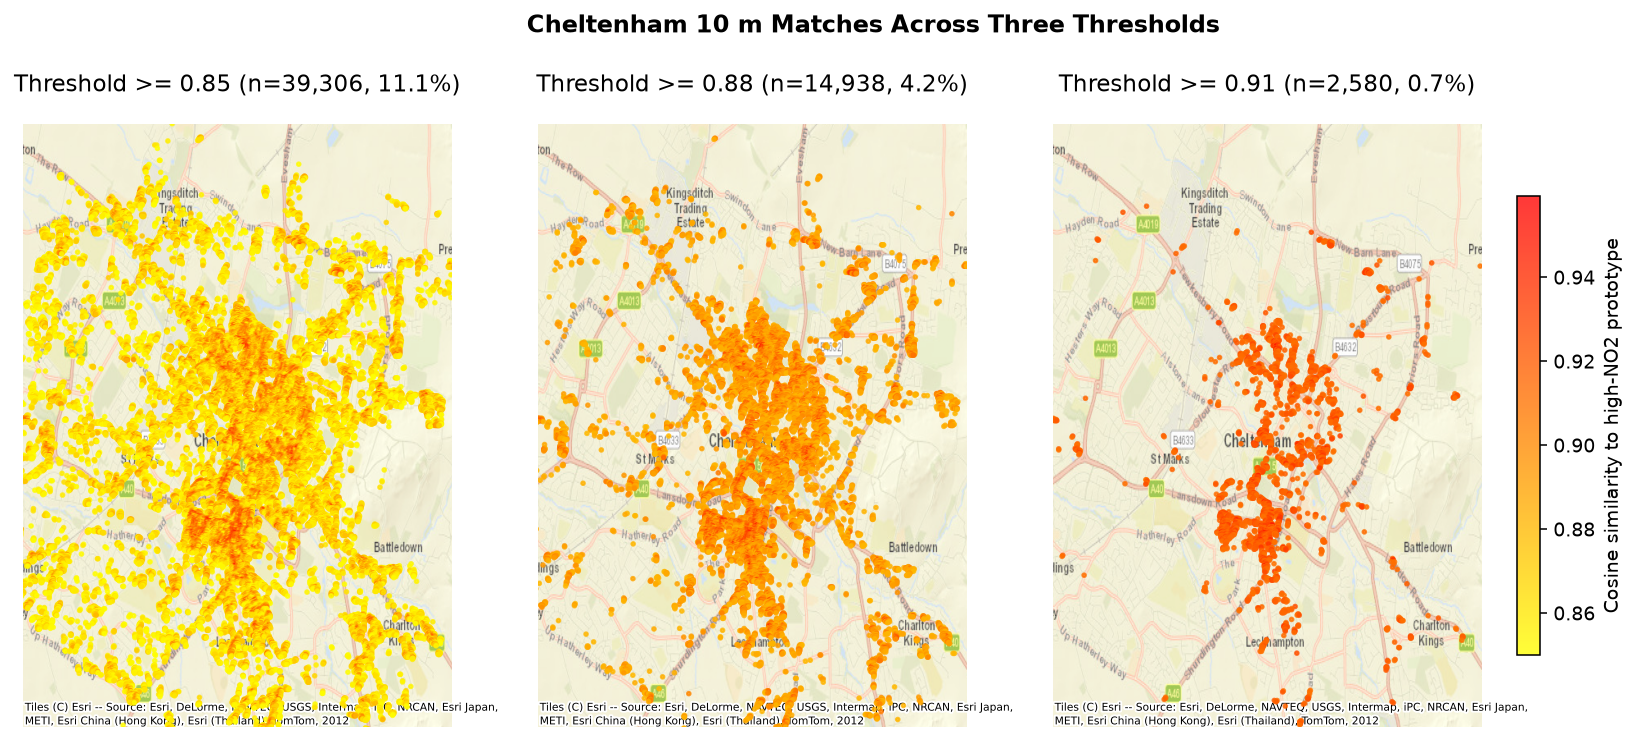

In [7]:
min_lon, min_lat, max_lon, max_lat = CHELTENHAM_BBOX
bx, by = rasterio.warp.transform("EPSG:4326", "EPSG:3857", [min_lon, max_lon], [min_lat, max_lat])

fig, axes = plt.subplots(1, len(THRESHOLDS), figsize=(5.4 * len(THRESHOLDS), 5.6))
if len(THRESHOLDS) == 1:
    axes = [axes]

for ax, thresh in zip(axes, THRESHOLDS):
    match_mask = sims >= thresh
    ax.set_xlim(bx[0], bx[1])
    ax.set_ylim(by[0], by[1])
    cx.add_basemap(ax, source=cx.providers.Esri.WorldStreetMap, alpha=0.72, attribution_size=5.5, zorder=1)
    sc = ax.scatter(
        mx[match_mask],
        my[match_mask],
        c=sims[match_mask],
        cmap="autumn_r",
        vmin=min(THRESHOLDS),
        vmax=float(sims.max()),
        s=3.5,
        alpha=0.78,
        zorder=3,
    )
    ax.set_axis_off()
    ax.set_title(f"Threshold >= {thresh:.2f} (n={match_mask.sum():,}, {match_mask.mean():.1%})")

fig.colorbar(sc, ax=axes, shrink=0.76, pad=0.02, label="Cosine similarity to high-NO2 prototype")
fig.suptitle("Cheltenham 10 m Matches Across Three Thresholds", fontsize=12.5, fontweight="bold", y=1.02)
plt.show()


## 6. Interactive street map with threshold slider

Run this to get an interactive playground for this small research project. 

Move the slider to filter 10 m pixels by cosine similarity and zoom into individual roads.


In [ ]:
import ipywidgets as widgets

center_lat = (min_lat + max_lat) / 2
center_lon = (min_lon + max_lon) / 2

def render_interactive_map(threshold: float = 0.88) -> None:
    match_idx = np.flatnonzero(sims >= threshold)
    m = folium.Map(location=[center_lat, center_lon], zoom_start=13, tiles=None)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Esri",
        name="Street Map",
        opacity=0.85,
    ).add_to(m)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
        attr="Esri",
        name="Light Gray (Translucent)",
        opacity=0.7,
        show=False,
    ).add_to(m)

    fg = folium.FeatureGroup(name=f"Matches >= {threshold:.2f} (top 2,000 of {len(match_idx):,})")
    top_order = match_idx[np.argsort(sims[match_idx])[::-1][:2000]]
    for idx in top_order:
        folium.CircleMarker(
            location=[float(lats[idx]), float(lons[idx])],
            radius=2.8,
            color="#d62728",
            fill=True,
            fill_color="#d62728",
            fill_opacity=0.65,
            weight=0,
            tooltip=f"sim={sims[idx]:.3f}",
        ).add_to(fg)
    fg.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    print(f"Showing top {len(top_order):,} of {len(match_idx):,} pixels >= {threshold:.2f}")
    display(m)

widgets.interact(
    render_interactive_map,
    threshold=widgets.FloatSlider(value=0.88, min=0.80, max=0.95, step=0.01, description="Threshold:", continuous_update=False),
);


interactive(children=(FloatSlider(value=0.88, continuous_update=False, description='Threshold:', max=0.95, min…